# Reproducing *Neural compression vs. wavelet-ℓ1 summaries*

Companion notebook for Tersenov et al. (2026). It is meant to be read top to bottom, and to
be runnable — nothing below is a stored picture being echoed back. Every table is computed
from data in this repository, and every figure is drawn by running its generator.

| | what it does | cost |
|---|---|---|
| **A** | rebuilds Table 1, then recomputes it from the per-observation posteriors | seconds, CPU, no download |
| **B** | draws the paper's 12 figures, one cell each | seconds–minutes each; needs the data record |
| **C** | retrains one compressor end to end | ~1 h, GPU; off by default |

**A needs nothing but this checkout.** B and C read the Zenodo record — set `$NN_L1_SBI_DATA`
to it, or unpack it into `data/zenodo/`. Whatever is unavailable is reported, never faked.

In [1]:
import os
import sys
from pathlib import Path

try:                                  # installed: pip install -e .
    import nn_l1_sbi
except ModuleNotFoundError:           # bare checkout: put src/ on the path
    _root = Path(os.environ.get("NN_L1_SBI_REPO") or next(
        p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file()))
    sys.path.insert(0, str(_root / "src"))

import numpy as np
from IPython.display import Markdown, display

from nn_l1_sbi.table1 import bundle

display(Markdown(f"Reading the committed Table-1 bundle from `{bundle.bundle_dir()}`."))

Reading the committed Table-1 bundle from `/path/to/nn_l1_sbi/data/table1`.

---
# A · Table 1

FoM₃ = 1 / √det Cov(Ω_m, σ₈, w₀), as a median over 9000 mock observations, with the marginal
widths beside it. Four rules define the entries:

1. the **±** is the spread over three *pre-ensemble* compressor seeds, as `std/mean`, rescaled onto the central;
2. the **central** is the published value where one exists, else the retrained one;
3. the **single→ensemble shift is a bias** — reported on its own, never inside the ±;
4. the **marginals** follow the row's quoted estimator, by the same relative rule.

Implemented in `nn_l1_sbi/table1/bundle.py`; `docs/NOTE_FOM_ERROR_BARS.md` says why each rule
is what it is.

### A.1 · Build the table from the 48 committed digests

In [2]:
arms, refs = bundle.load_all()
rows = bundle.build_rows(arms)
display(Markdown(bundle.table_markdown(rows)))

| arm | frame | quoted | FoM₃ | σ(Ω_m) | σ(σ₈) | σ(w₀) | bias % |
|---|---|---|--:|--:|--:|--:|--:|
| l1 auto | no-BNT | single | **2448 ± 27** | 0.0503 ± 0.0001 | 0.0799 ± 0.0007 | 0.2340 ± 0.0022 | -9.4 |
| l1 auto | BNT | ensemble | **388 ± 43** | 0.0861 ± 0.0035 | 0.1725 ± 0.0082 | 0.3191 ± 0.0057 | -12.2 |
| l1 +conv | no-BNT | single | **2671 ± 133** | 0.0518 ± 0.0011 | 0.0814 ± 0.0021 | 0.2366 ± 0.0030 | -5.4 |
| l1 +conv | BNT | ensemble | **458 ± 15** \* | 0.0836 ± 0.0010 | 0.1643 ± 0.0021 | 0.3155 ± 0.0028 | -9.5 |
| l1 +product | no-BNT | single | **3045 ± 183** | 0.0462 ± 0.0006 | 0.0746 ± 0.0008 | 0.2271 ± 0.0045 | -8.0 |
| l1 +product | BNT | ensemble | **718 ± 29** | 0.0721 ± 0.0008 | 0.1293 ± 0.0025 | 0.2994 ± 0.0021 | -17.8 |
| l1 +conv+product | no-BNT | single | **3255 ± 200** | 0.0452 ± 0.0007 | 0.0714 ± 0.0014 | 0.2202 ± 0.0041 | -7.3 |
| l1 +conv+product | BNT | ensemble | **704 ± 76** \* | 0.0755 ± 0.0024 | 0.1349 ± 0.0051 | 0.3030 ± 0.0077 | -10.4 |
| joint l1 | no-BNT | ensemble | **3371 ± 96** | 0.0440 ± 0.0005 | 0.0716 ± 0.0005 | 0.2234 ± 0.0029 | -11.2 |
| joint l1 | BNT | ensemble | **2424 ± 208** | 0.0513 ± 0.0014 | 0.0856 ± 0.0023 | 0.2366 ± 0.0061 | -20.4 |
| CNN | no-BNT | single | **3326 ± 14** | 0.0444 ± 0.0004 | 0.0702 ± 0.0005 | 0.2288 ± 0.0007 | -2.6 |
| CNN | BNT | single | **3186 ± 19** | 0.0461 ± 0.0005 | 0.0730 ± 0.0006 | 0.2311 ± 0.0011 | -1.7 |

**±** — spread over the three pre-ensemble compressor seeds, as `std/mean`, rescaled onto the quoted central; the marginals follow the same rule.  
**\*** — no published value (new result); the central is the retrained one.  
**bias %** — the single→ensemble shift, reported separately and never folded into the ±.

### A.2 · Check every number against the published tables

`verify` re-checks each rebuilt value against the four cross-check tables in `data/table1/`,
and fails if the *count* of checks changes — so a suite that quietly stopped checking cannot
report success.

In [3]:
bundle.verify(rows, refs)

OK: 374 checks passed against all four committed cross-check tables (both bias conventions included).


374

### A.3 · Where the published and retrained values differ

The published centrals come from the original run; rebuilding retrains them. They differ by
up to ~13%, which is exactly why rule 2 quotes the published central and rule 1 carries the ±
as a *relative* spread rather than an absolute one.

In [4]:
print(bundle.published_vs_retrained(rows))

arm                 frame   quoted      published  retrained   delta %  +- (rel %)
----------------------------------------------------------------------------------
l1 auto             no-BNT  single           2448     2776.9     +13.4        1.10
l1 auto             BNT     ensemble          388      390.7      +0.7       11.07
l1 +conv            no-BNT  single           2671     2720.2      +1.8        4.99
l1 +conv            BNT     ensemble          new      457.6        --        3.30
l1 +product         no-BNT  single           3045     3231.8      +6.1        6.01
l1 +product         BNT     ensemble          718      758.3      +5.6        4.09
l1 +conv+product    no-BNT  single           3255     3564.9      +9.5        6.14
l1 +conv+product    BNT     ensemble          new      703.9        --       10.81
joint l1            no-BNT  ensemble         3371     3379.5      +0.3        2.84
joint l1            BNT     ensemble         2424     2405.2      -0.8        8.59
CNN 

---
### A.4 · Now compute it yourself, one level down

Everything above reduces per-arm digests. Those digests were themselves reduced from the
**per-observation posteriors** — one 3×3 covariance of (Ω_m, σ₈, w₀) for each of the 9000
mocks. That file ships too (430 kB, the ℓ1 auto / no-BNT arm), so the reduction can be redone
here instead of trusted.

Applying the definition FoM₃ = 1/√det Cov to all 9000 covariances should return the digest's
number exactly.

In [5]:
d = bundle.load_per_obs("auto_nobnt_s41")          # 9000 posterior covariances
fom = bundle.fom3_from_cov(d["cov"])               # the definition, applied directly

digest = bundle.load(arms["l1 auto, no-BNT"]["singles"]["s41"])["fom3"]
print(f"{'recomputed from ' + str(len(fom)) + ' covariances':<40}: {np.median(fom):.6f}")
print(f"{'stored in the digest':<40}: {digest:.6f}")
print(f"{'agree to 1e-9':<40}: {np.isclose(np.median(fom), digest, rtol=0, atol=1e-9)}")

recomputed from 9000 covariances        : 2776.934432
stored in the digest                    : 2776.934432
agree to 1e-9                           : True


### A.5 · And the error bar on that median

The 9000 mocks are 180 sky patches × 50 noise realisations, so they are **not** 9000
independent draws — values sharing a patch share its signal. The honest error on the median
therefore resamples *patches*, keeping all 50 realisations of each.

This runs 10⁴ bootstrap replicates now; it should land on the `median_se` stored in
`TABLE1_ERRORBARS_V2.json`.

In [6]:
se, lo, hi = bundle.block_bootstrap(fom, d["patch"], n_rep=10_000)
stored = bundle.load("TABLE1_ERRORBARS_V2.json")["l1 auto, no-BNT"]["median_se"]

print(f"block bootstrap over 180 patches, 10,000 replicates")
print(f"  SE(median)      : {se:.2f}")
print(f"  68% interval    : [{lo:.1f}, {hi:.1f}]")
print(f"  stored value    : {stored:.2f}")
print()
print(f"This is the sub-percent term quoted in the Table 1 caption: {100*se/np.median(fom):.2f}%")
print("of the median -- an order of magnitude below the ~1.1% compressor-seed spread that")
print("sets the quoted error bar for this arm.")

block bootstrap over 180 patches, 10,000 replicates
  SE(median)      : 4.95
  68% interval    : [2771.2, 2781.3]
  stored value    : 4.95

This is the sub-percent term quoted in the Table 1 caption: 0.18%
of the median -- an order of magnitude below the ~1.1% compressor-seed spread that
sets the quoted error bar for this arm.


---
# B · The figures in the paper

One cell per figure, in manuscript order — each is an `\includegraphics` in the paper, and
each cell *runs its generator* rather than loading a stored image. A figure whose input is
absent says which input, and what produces it.

Diagnostics the repository ships but the paper does not use (`fig:embed`, `fig:leak`,
`fig:bntwhiten`, `fig:w0`) are not shown here; see `docs/FIGURE_MAP.md`.

In [7]:
from nn_l1_sbi.figures import gallery
display(Markdown(gallery.status_markdown()))

**7 of 12** paper figures can be drawn from the data present here.

- data root: `/path/to/nn_l1_sbi_data`
- figures written to: `/path/to/nn_l1_sbi_out/figures`
- style sheet: found

| figure | paper section | inputs | what it shows |
|---|---|:--:|---|
| `fig:data` | 3 Statistics | yes | the 4 auto and 12 cross channels of one 10 deg patch |
| `fig:l1` | 3 Statistics | **no** (0/1) | per-channel l1 histograms against SNR, at two values of sigma_8 |
| `fig:l1joint` | 3 Statistics | yes | the joint l1 (u_i, u_j) cell map for a representative bin |
| `fig:pipeline` | 4 Inference | yes | the end-to-end pipeline schematic |
| `fig:ablation` | 5 Results | **no** (0/2) | the operator completeness ladder, auto to +conv to +product to joint |
| `fig:cp` | 5 Results | yes | FoM3 and marginal violins across the 9000 mocks, for three arms |
| `fig:corner` | 5 Results | yes | the mean-observation posterior, CNN against joint l1 |
| `fig:bnt` | 6 BNT | yes | what the BNT transform costs the analytic and the learned summaries |
| `fig:tarp` | A0 Calibration | **no** (0/1) | TARP coverage in the no-BNT frame |
| `fig:tarp_bnt` | A0 Calibration | **no** (0/1) | TARP coverage in the BNT frame |
| `fig:sbc` | A0 Calibration | **no** (0/3) | SBC rank histograms for the three quoted arms |
| `fig:fisher` | A4 Fisher | yes | per-bin diagonal Fisher information of the 800-D auto l1 |

### `fig:data` · 3 Statistics

fig:data   (3 Statistics)   ->  fig_data_flatlocal.pdf


  drawn in 3.8 s: fig_data_flatlocal.pdf


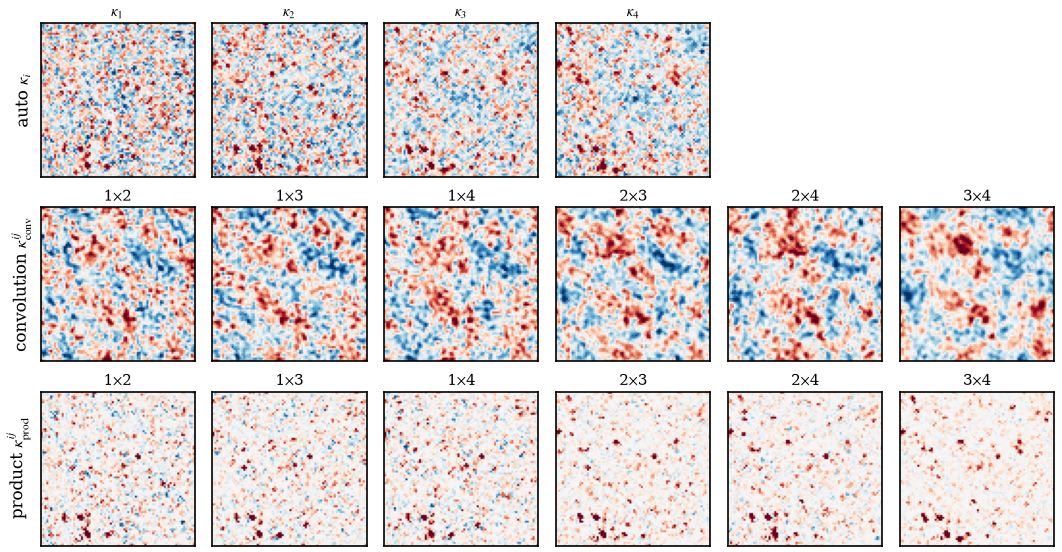

In [8]:
gallery.show("fig:data")

### `fig:l1` · 3 Statistics

In [9]:
gallery.show("fig:l1")

fig:l1   (3 Statistics)   ->  fig_l1_hist_vs_s8.pdf
  not drawn: 0/1 inputs present
    missing  /path/to/nn_l1_sbi_data/derived/l1_hist_vs_s8_levels_cache.npz
  produced by: no surviving generator for the level cache
  Nothing is substituted; see docs/FIGURE_MAP.md.


### `fig:l1joint` · 3 Statistics

fig:l1joint   (3 Statistics)   ->  fig_l1_joint_cellmap.pdf


  drawn in 2.6 s: fig_l1_joint_cellmap.pdf


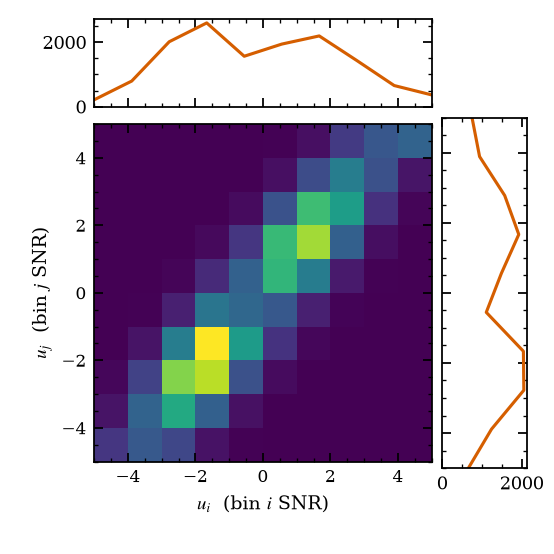

In [10]:
gallery.show("fig:l1joint")

### `fig:pipeline` · 4 Inference

fig:pipeline   (4 Inference)   ->  fig_pipeline.pdf


  drawn in 2.4 s: fig_pipeline.pdf


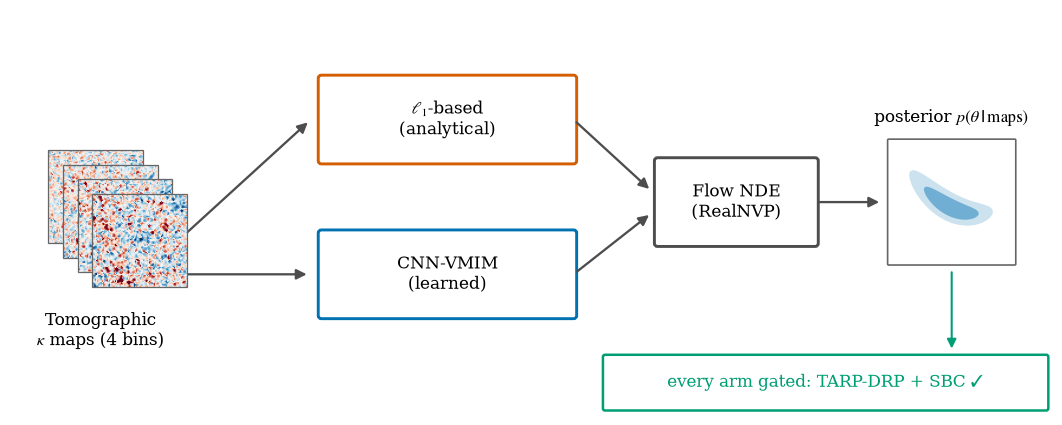

In [11]:
gallery.show("fig:pipeline")

### `fig:ablation` · 5 Results

In [12]:
gallery.show("fig:ablation")

fig:ablation   (5 Results)   ->  fig_ablation.pdf
  not drawn: 0/2 inputs present
    missing  /path/to/nn_l1_sbi_data/analysis/flatsky_cross_2026_06/analytical_nde_match/operator_realnvp/conv/n9000/median_summary.json
    missing  /path/to/nn_l1_sbi_data/analysis/flatsky_cross_2026_06/analytical_nde_match/operator_realnvp/both/n9000/median_summary.json
  produced by: nn_l1_sbi.inference.population_sweep, on the operator_realnvp arms
  Nothing is substituted; see docs/FIGURE_MAP.md.


### `fig:cp` · 5 Results

fig:cp   (5 Results)   ->  fig_cp_fom3_bars.pdf


  drawn in 3.3 s: fig_cp_fom3_bars.pdf


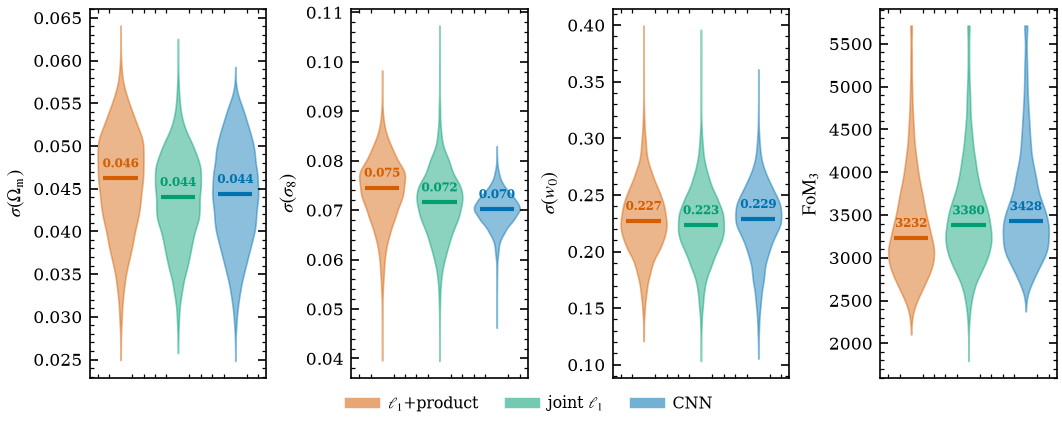

In [13]:
gallery.show("fig:cp")

### `fig:corner` · 5 Results

fig:corner   (5 Results)   ->  fig_corner_cnn_vs_l1.pdf


  drawn in 7.4 s: fig_corner_cnn_vs_l1.pdf


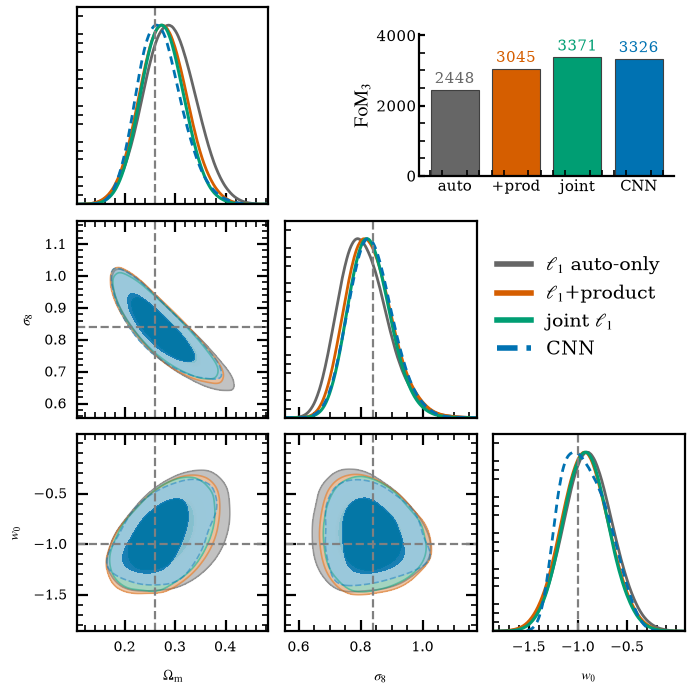

In [14]:
gallery.show("fig:corner")

### `fig:bnt` · 6 BNT

fig:bnt   (6 BNT)   ->  fig_bnt_analytic.pdf + fig_bnt_learned.pdf


  drawn in 16.2 s: fig_bnt_analytic.pdf, fig_bnt_analytic_noprod.pdf, fig_bnt_learned.pdf
  (also written, not a paper panel: fig_bnt_analytic_noprod.png)


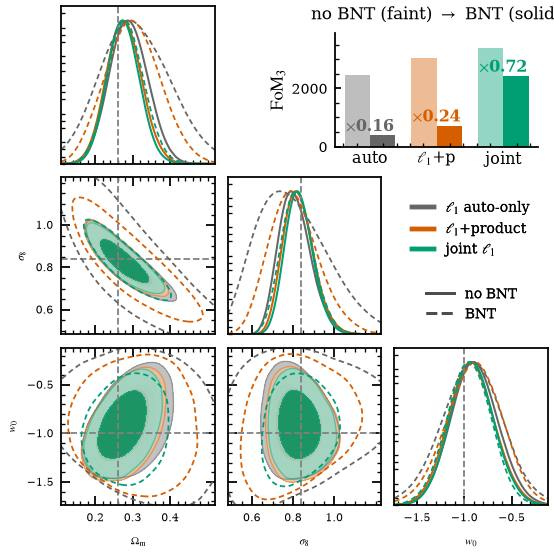

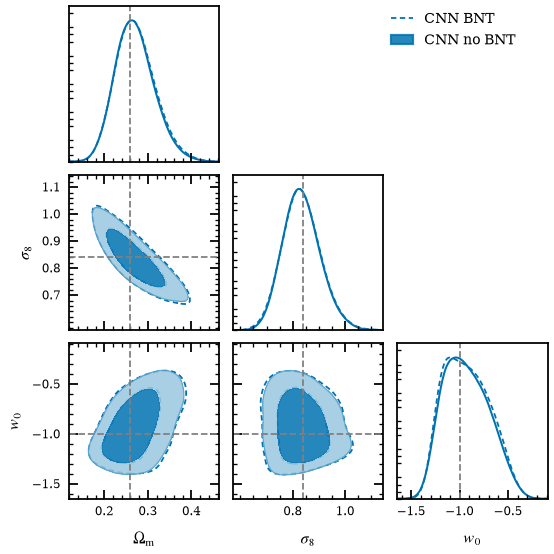

In [15]:
gallery.show("fig:bnt")

### `fig:tarp` · A0 Calibration

In [16]:
gallery.show("fig:tarp")

fig:tarp   (A0 Calibration)   ->  fig_tarp_overlay.pdf
  not drawn: 0/1 inputs present
    missing  /path/to/nn_l1_sbi_data/derived/tarp_proper_bands.npz
  produced by: nn_l1_sbi.inference.run_tarp_coverage
  Nothing is substituted; see docs/FIGURE_MAP.md.


### `fig:tarp_bnt` · A0 Calibration

In [17]:
gallery.show("fig:tarp_bnt")

fig:tarp_bnt   (A0 Calibration)   ->  fig_tarp_overlay_bnt.pdf
  not drawn: 0/1 inputs present
    missing  /path/to/nn_l1_sbi_data/derived/tarp_proper_bands_bnt.npz
  produced by: nn_l1_sbi.inference.run_tarp_coverage
  Nothing is substituted; see docs/FIGURE_MAP.md.


### `fig:sbc` · A0 Calibration

In [18]:
gallery.show("fig:sbc")

fig:sbc   (A0 Calibration)   ->  fig_sbc_hist_combined.pdf
  not drawn: 0/3 inputs present
    missing  /path/to/nn_l1_sbi_data/analysis/flatsky_cross_2026_06/analytical_nde_match/gate_l1none_rnvp/tarp_drp/dumps/l1none_rnvp_*/seed_*/n*_m*/posterior_samples.npz
    missing  /path/to/nn_l1_sbi_data/analysis/flatsky_cross_2026_06/analytical_nde_match/gate_l1product_rnvp/tarp_drp/dumps/l1product_rnvp_*/seed_*/n*_m*/posterior_samples.npz
    missing  /path/to/nn_l1_sbi_data/analysis/flatsky_cross_2026_06/cnn_phase/arch_sweep_2026_06_13/gate_c_resnet18/dumps/resnet18_rnvp_*/seed_*/n*_m*/posterior_samples.npz
  produced by: nn_l1_sbi.inference.run_joint_gate_c  [the TARP-DRP gate dumps]
  Nothing is substituted; see docs/FIGURE_MAP.md.


### `fig:fisher` · A4 Fisher

fig:fisher   (A4 Fisher)   ->  fig_fisher.pdf


  drawn in 10.5 s: fig_fisher.pdf


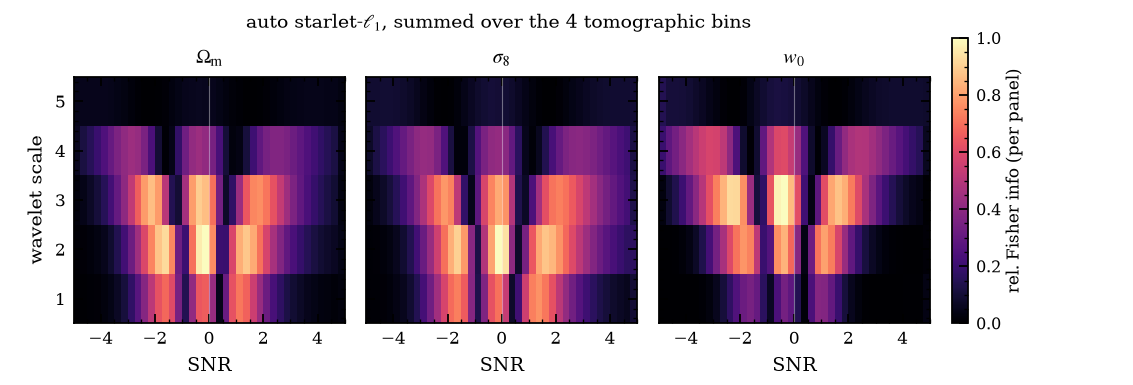

In [19]:
gallery.show("fig:fisher")

---

# Section C — Optional end-to-end retrain (GPU, ~1 h)

**Opt-in only.** Every cell below starts with

```python
if os.environ.get("NN_L1_SBI_GPU") != "1":
    ...skip...
```

so a CPU reader can Run-All safely. To enable:

```bash
export NN_L1_SBI_GPU=1
export NN_L1_SBI_DATA=/path/to/the/writable/data/root     # raw l1 caches live here
```

What it does: retrain **one** VMIM compressor seed on the $\ell_1$ **auto, no-BNT** arm
(`vmim_from_cache`, 30 000 steps, ~35 min on one A100), then run the population sweep over the
9000 mocks on it (`population_sweep`, ~4 min), then compare the resulting FoM$_3$ against this
repository's own retrained value for that arm.

### Why it will not match exactly

The dominant term in the FoM$_3$ error budget is the **compressor training seed**: retraining the
compressor and re-running everything downstream moves FoM$_3$ by **~5–7 %**
(`docs/NOTE_FOM_ERROR_BARS.md` §3). Everything else is smaller — the NDE seed / family
contributes < 1.2 %, and the median's own sampling error over 9000 clustered mocks is 0.1–3 %.
On top of that, GPU non-determinism means even *the same* seed will not land on the same number
twice. A 5 % gate is therefore deliberately loose but not vacuous.

### What it is compared against, and why

The gate target is the **mean of the three retrained singles** `s41/s42/s43` of
`l1 auto, no-BNT` in `data/table1/` — **≈ 2772** (A.3 prints the three values; A.5 prints the
offset). It is **not** the published 2448, and **not** the retrained ensemble 2511. Two reasons:

* **estimator.** A single retrained compressor must be compared against retrained *singles*.
  In every row the 3-compressor ensemble sits below the mean of its singles — by 2–20 %, and
  by 9.4 % for this very arm — because pooling nine flows widens the posterior. "Never compare
  a retrained single against a published ensemble, or vice versa"
  (`scripts/slurm/CAMPAIGN_REFERENCE.md` §2).
* **provenance.** The published numbers were produced on different hardware before this
  reproduction. A.5 prints the retrained-vs-published offset for each of the ten rows that
  have a published value, every row in its own quoted estimator; they run from −1.2 % to
  +13.4 %, and this arm's is the *largest* of the ten (single vs single, +13.4 %). Gating on
  2448 would therefore fail a perfectly healthy rerun. (`CAMPAIGN_REFERENCE.md` §4 tabulates
  a different, ensemble-matched subset, +0.7 % to +5.6 % — not the same quantity as A.5.)
  The cell below prints the published comparison too, but does not gate on it.

### C.1 — Guard, configuration, preflight *(instant; skipped without `NN_L1_SBI_GPU=1`)*

Checks the inputs exist and prints the exact two commands that will be run. Nothing is trained
here.

In [20]:
if os.environ.get("NN_L1_SBI_GPU") != "1":
    print("Section C skipped (CPU-safe). Set NN_L1_SBI_GPU=1 to enable; needs 1 GPU and ~1 h.")
else:
    GPU_DATA = Path(os.environ.get("NN_L1_SBI_DATA", "")).expanduser()
    SEED = int(os.environ.get("NN_L1_SBI_SEED", "41"))
    TAG = f"none_nobnt_s{SEED}_repro"
    ARM_LABEL = f"auto_nobnt_s{SEED}_repro"

    # Flags below are the ones that produced Table 1; cross-check against
    # scripts/slurm/vmim_none_nobnt.slurm and scripts/slurm/sw_auto_nobnt_s41.slurm.
    CACHE_DIR = GPU_DATA / "l1_datavector_cache" / "flat_local_none"
    FID_NPZ = GPU_DATA / "fid_raw_none.npz"
    OUT_CACHE = GPU_DATA / "vmim" / TAG
    OUT_FID = OUT_CACHE / "fiducial_summaries.npz"
    SWEEP_OUT = GPU_DATA / "sweeps" / ARM_LABEL

    VMIM_CMD = [sys.executable, "-u", "-m", "nn_l1_sbi.compression.vmim_from_cache",
                "--cache-dir", str(CACHE_DIR),
                "--fid-npz", str(FID_NPZ),
                "--out-cache", str(OUT_CACHE),
                "--out-fid", str(OUT_FID),
                "--summary-dim", "10", "--hidden", "256,256",
                "--nf-layers", "4", "--nf-hidden", "128",
                "--steps", "30000", "--seed", str(SEED),
                "--preproc-transform", "log1p-zscore", "--clip-value", "5",
                "--min-feature-variance", "1e-5",
                "--max-minutes", "35", "--cuda-visible-devices", "0"]
    SWEEP_CMD = [sys.executable, "-u", "-m", "nn_l1_sbi.inference.population_sweep",
                 "--arm-dir", str(OUT_CACHE),
                 "--arm-label", ARM_LABEL,
                 "--out", str(SWEEP_OUT),
                 "--seeds", "41,42,43", "--n-obs", "9000",
                 "--max-perm", "50", "--m-samples", "2000"]

    missing = [p for p in (CACHE_DIR, FID_NPZ) if not p.exists()]
    print(f"data root : {GPU_DATA}")
    print(f"seed      : {SEED}   (the paper's compressor seeds are 41, 42, 43)")
    print(f"cache-dir : {CACHE_DIR}  {'OK' if CACHE_DIR.exists() else 'MISSING'}")
    print(f"fid-npz   : {FID_NPZ}  {'OK' if FID_NPZ.exists() else 'MISSING'}")
    print(f"out       : {OUT_CACHE}  ->  {SWEEP_OUT}")
    print()
    print("step 1 (~35 min):", " ".join(VMIM_CMD[2:]))
    print()
    print("step 2 (~4 min) :", " ".join(SWEEP_CMD[2:]))
    if missing:
        print()
        print("PREFLIGHT FAILED -- these inputs are absent, so C.2/C.3 will not run:")
        for p in missing:
            print("   ", p)
        print("The raw 800-D l1 datavector caches are the 35 GB tier; they are not on Zenodo.")
    else:
        print()
        print("preflight OK.")
    C_READY = not missing

Section C skipped (CPU-safe). Set NN_L1_SBI_GPU=1 to enable; needs 1 GPU and ~1 h.


### C.2 — Retrain one VMIM compressor *(GPU, ~35 min; skipped without `NN_L1_SBI_GPU=1`)*

`nn_l1_sbi.compression.vmim_from_cache`, with the flags of
`scripts/slurm/vmim_none_nobnt.slurm` — summary dim 10, hidden 256,256, RealNVP 4×128,
30 000 steps, `log1p-zscore` preprocessing with clip 5 and min-variance 1e-5. Output goes to a
`*_repro` directory, so nothing that Table 1 depends on is overwritten.

The SLURM job runs the same command under `srun` on an allocated node; here it runs directly on
whatever GPU the notebook kernel sees.

In [21]:
if os.environ.get("NN_L1_SBI_GPU") != "1":
    print("Section C skipped (CPU-safe). Set NN_L1_SBI_GPU=1 to enable.")
elif not C_READY:
    print("C.1 preflight failed -- not training. See the missing inputs above.")
else:
    env = dict(os.environ, PYTHONPATH=f"{SRC}{os.pathsep}{os.environ.get('PYTHONPATH', '')}",
               TF_CPP_MIN_LOG_LEVEL="3", XLA_PYTHON_CLIENT_PREALLOCATE="false")
    t0 = time.time()
    proc = subprocess.run(VMIM_CMD, cwd=str(REPO), env=env, text=True,
                          capture_output=True, timeout=4 * 3600)
    print(f"exit={proc.returncode}  {(time.time() - t0) / 60:.1f} min")
    for line in proc.stdout.strip().splitlines()[-20:]:
        print("   ", line)
    if proc.returncode != 0:
        for line in proc.stderr.strip().splitlines()[-20:]:
            print("   |", line)
        raise RuntimeError("vmim_from_cache failed -- see stderr above")
    meta = OUT_CACHE / "l1_cache_meta.npz"
    if meta.exists():
        z = np.load(meta, allow_pickle=True)
        print("cache meta:", {k: z[k].item() if z[k].shape == () else z[k].tolist()
                              for k in ("summary_dim", "steps_run", "best_step", "best_val", "seed")
                              if k in z})

Section C skipped (CPU-safe). Set NN_L1_SBI_GPU=1 to enable.


### C.3 — Population sweep on the new compressor *(GPU, ~4 min; skipped without `NN_L1_SBI_GPU=1`)*

`nn_l1_sbi.inference.population_sweep` with the flags of
`scripts/slurm/sw_auto_nobnt_s41.slurm`: NDE seeds 41,42,43 pooled, 9000 mock observations
(180 patches × 50 noise realisations), 2000 posterior draws each. Writes
`median_summary.json`, `per_patch_metrics.npz` and `per_obs_samples.npy` (~216 MB) into the
`*_repro` sweep directory.

In [22]:
if os.environ.get("NN_L1_SBI_GPU") != "1":
    print("Section C skipped (CPU-safe). Set NN_L1_SBI_GPU=1 to enable.")
elif not C_READY:
    print("C.1 preflight failed -- not sweeping.")
else:
    env = dict(os.environ, PYTHONPATH=f"{SRC}{os.pathsep}{os.environ.get('PYTHONPATH', '')}",
               TF_CPP_MIN_LOG_LEVEL="3", XLA_PYTHON_CLIENT_PREALLOCATE="false")
    t0 = time.time()
    proc = subprocess.run(SWEEP_CMD, cwd=str(REPO), env=env, text=True,
                          capture_output=True, timeout=4 * 3600)
    print(f"exit={proc.returncode}  {(time.time() - t0) / 60:.1f} min")
    for line in proc.stdout.strip().splitlines()[-20:]:
        print("   ", line)
    if proc.returncode != 0:
        for line in proc.stderr.strip().splitlines()[-20:]:
            print("   |", line)
        raise RuntimeError("population_sweep failed -- see stderr above")

Section C skipped (CPU-safe). Set NN_L1_SBI_GPU=1 to enable.


### C.4 — Compare against Table 1 *(instant; skipped without `NN_L1_SBI_GPU=1`)*

Gate: the new FoM$_3$ must be within `NN_L1_SBI_FOM_TOL` (default **5 %**) of
`BY_LABEL["l1 auto, no-BNT"]["mean"]` — the mean of the three **retrained singles** in
`data/table1/`, **≈ 2772**. That is the quantity the assertion below uses, and it is neither
the published 2448 nor the retrained ensemble 2511; the cell prints all three so the comparison
cannot be misread.

Read the result honestly. A 3 % miss is a compressor seed; a 40 % miss is a broken pipeline. If
the gate fails by a little, look at the spread of the three committed singles printed alongside —
it is the empirical scale of exactly this effect.

In [23]:
if os.environ.get("NN_L1_SBI_GPU") != "1":
    print("Section C skipped (CPU-safe). Set NN_L1_SBI_GPU=1 to enable.")
else:
    summary = SWEEP_OUT / "median_summary.json" if C_READY else None
    if summary is None:
        print("nothing to check: the C.1 preflight failed, so C.2/C.3 did not run.")
    elif not summary.exists():
        print(f"nothing to check: {summary} does not exist -- run C.2 and C.3 first.")
    else:
        with open(summary) as fh:
            got = json.load(fh)
        ref = BY_LABEL["l1 auto, no-BNT"]
        target = ref["mean"]                       # mean of the three retrained singles
        tol = float(os.environ.get("NN_L1_SBI_FOM_TOL", "0.05"))
        delta = (got["fom3"] - target) / target

        print(f"retrained now      : FoM3 = {got['fom3']:.1f}   "
              f"(arm {got['arm']}, n = {got['n']}, n_members = {got['n_members']})")
        print(f"committed singles  : {['%.1f' % v for v in ref['per_seed']]}  "
              f"mean {target:.1f}  std {ref['std']:.1f}  ({100 * ref['rel']:.2f} %)")
        print(f"delta vs singles   : {100 * delta:+.2f} %   (gate: +-{100 * tol:.0f} %)")
        print(f"committed ensemble : {ref['ensemble']:.1f}   "
              f"(do NOT compare a single against this)")
        print(f"published (paper)  : {ref['published']}   "
              f"delta {100 * (got['fom3'] - ref['published']) / ref['published']:+.1f} % "
              f"-- reported, not gated (see the section header)")
        for k, lab in (("sigma_Om", "sigma(Om)"), ("sigma_s8", "sigma(s8)"),
                       ("sigma_w0", "sigma(w0)")):
            j = PARAMS.index(k)
            print(f"{lab:<19}: {got[k]:.4f}   committed s41 {ref['sigma'][j]:.4f}   "
                  f"{100 * (got[k] - ref['sigma'][j]) / ref['sigma'][j]:+.1f} %")

        assert abs(delta) <= tol, (
            f"FoM3 {got['fom3']:.1f} is {100 * delta:+.1f} % from the committed retrained "
            f"singles mean {target:.1f} -- outside the +-{100 * tol:.0f} % gate. Compressor-seed "
            "variance is ~5-7 % (docs/NOTE_FOM_ERROR_BARS.md section 3), so a small overshoot is "
            "seed noise; a large one is a pipeline problem.")
        print(f"\nOK: within +-{100 * tol:.0f} % of the committed retrained value.")

Section C skipped (CPU-safe). Set NN_L1_SBI_GPU=1 to enable.


---

## Provenance

| what | where |
|---|---|
| Table-1 inputs (committed, 43 kB) | `data/table1/` — see its `README.md` for the full schema |
| error-bar definition | `docs/NOTE_FOM_ERROR_BARS.md` |
| figure → data → generator map | `docs/FIGURE_MAP.md`, `src/nn_l1_sbi/figures/_data.py` |
| the exact SLURM recipes | `scripts/slurm/` (`vmim_*.slurm`, `sw_*.slurm`) |
| verified constants (geometry, noise, FoM$_3$) | `scripts/slurm/CAMPAIGN_REFERENCE.md` §3 |
